In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df_1 = pd.read_csv("2001-2010.csv")
df_2 = pd.read_csv("2011-2020.csv")
df_3 = pd.read_csv("2015-2024.csv")

In [4]:
df_1.head()

,Region and country of nationality,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010
0,REGION,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Total,"68,925","26,785","28,286","52,840","53,738","41,094","48,218","60,107","74,602","73,293"
2,Africa,"19,070","2,551","10,719","29,108","20,746","18,129","17,486","8,943","9,678","13,325"
3,Asia,"16,985","7,723","6,731","12,276","15,769","10,086","23,563","44,819","58,309","52,695"
4,Europe,"29,897","14,579","10,381","7,879","10,524","9,615","4,193","2,059","1,693","1,238"


In [5]:
# Keep non-overlapping year columns
years_df2 = [
    c
    for c in df_2.columns
    if c not in df_3.columns or c == "Region and country of nationality"
]
years_df1 = [
    c
    for c in df_1.columns
    if c not in df_2.columns or c == "Region and country of nationality"
]

df_comb = df_1[years_df1].merge(
    df_2[years_df2].merge(
        df_3, on="Region and country of nationality", how="outer"
    ),
    on="Region and country of nationality",
    how="outer",
)

In [6]:
df_comb.head()

,Region and country of nationality,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Afghanistan,"2,930","1,683","1,453",959,902,651,441,576,349,...,910,"2,740","1,320",800,"1,200",600,870,"1,620","6,590","14,680"
1,Africa,"19,070","2,551","10,719","29,108","20,746","18,129","17,486","8,943","9,678",...,"22,500","31,640","20,250","10,460","16,370","4,170","6,260","11,410","24,530","34,100"
2,Algeria,31,-,4,D,D,D,-,-,-,...,0,0,0,0,0,0,0,0,0,10
3,All other countries,49,31,29,18,20,23,25,31,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,All other countries1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,60,60,60,30,30,20,30,30,40,110


C:\Users\samho\AppData\Local\Temp\ipykernel_17668\1343323492.py:108: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(left=0.32, right=0.85, top=0.90, bottom=0.16)


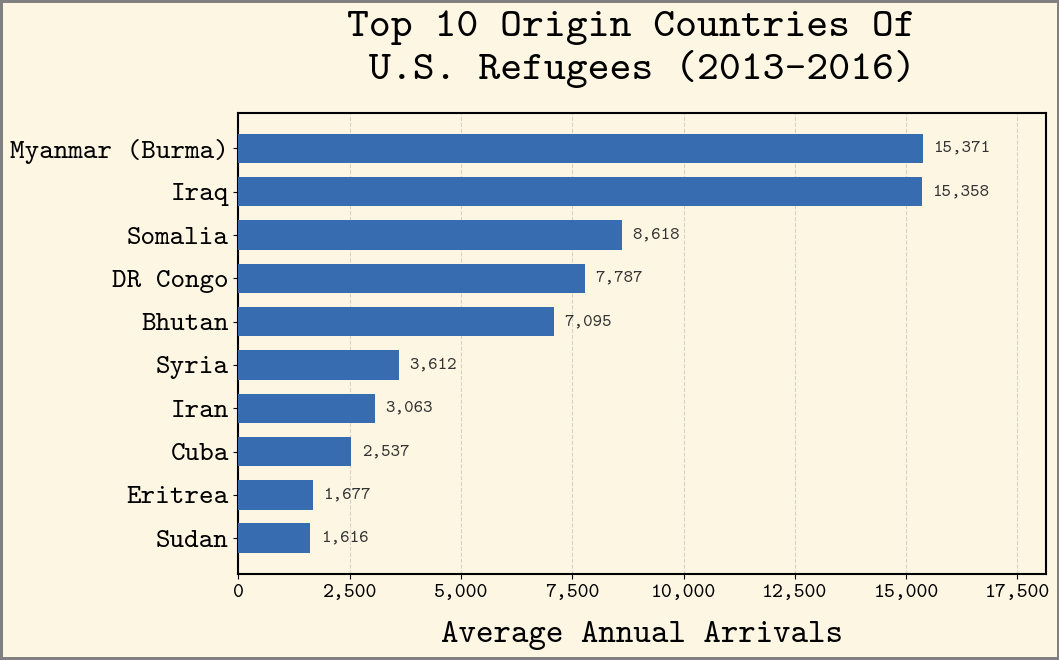

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Apply custom style
plt.style.use("btt_style")

country_col = "Region and country of nationality"

# 2. Prepare and clean data
df_work = df_comb.copy()
df_work[country_col] = df_work[country_col].astype(str).str.strip()

# 3. Filter for Obama's second term (FY 2013 to 2016)
year_cols = [
    c for c in df_work.columns if str(c).strip().isdigit() and 2013 <= int(c) <= 2016
]

for col in year_cols:
    df_work[col] = (
        df_work[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .replace({"-": "0", "D": "0"})
    )
    df_work[col] = pd.to_numeric(df_work[col], errors="coerce").fillna(0)

# Filter out regional aggregate/header rows common in DHS tables
summary_rows = [
    "Total",
    "Africa",
    "Asia",
    "Europe",
    "North America",
    "South America",
    "Oceania",
    "Unknown",
]
df_work = df_work[~df_work[country_col].isin(summary_rows)].copy()

# Clean up names for readability
name_replacements = {
    "Congo, Democratic Republic": "DR Congo",
    "Burma": "Myanmar (Burma)",
}
df_work[country_col] = df_work[country_col].replace(name_replacements)

# 4. Calculate average annual arrivals across FY 2013-2016
df_work["Annual_Average"] = df_work[year_cols].mean(axis=1)

# Group by country, take top 10, sort ascending so #1 is at top
df_top10 = (
    df_work.groupby(country_col)["Annual_Average"]
    .sum()
    .nlargest(10)
    .sort_values(ascending=True)
    .reset_index()
)

# 5. Build visualization
fig, ax = plt.subplots(figsize=(11, 7))

# Single uniform color for all bars
bar_color = "#386CB0"

bars = ax.barh(
    df_top10[country_col],
    df_top10["Annual_Average"],
    color=bar_color,
    edgecolor="none",
    height=0.68,
    zorder=3,
)

# Data labels at bar ends
max_val = df_top10["Annual_Average"].max()
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + (max_val * 0.015),
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        ha="left",
        fontsize=13,
        fontweight="bold",
        color="#333333",
    )

# Formatting & Titles
ax.set_title(
    "Top 10 Origin Countries Of \nU.S. Refugees (2013-2016)",
    pad=24,
    fontsize=30,
    fontweight="bold",
)
ax.set_xlabel("Average Annual Arrivals", labelpad=14, fontsize=24)
ax.set_xlim(0, max_val * 1.18)
ax.yaxis.set_tick_params(labelsize=20)
ax.xaxis.set_tick_params(labelsize=15)
ax.xaxis.set_major_formatter("{x:,.0f}")

# Gridlines
ax.grid(axis="x", linestyle="--", alpha=0.5, zorder=0)
ax.set_axisbelow(True)

# Spacing adjustment so labels and x-axis title aren't clipped
plt.subplots_adjust(left=0.32, right=0.85, top=0.90, bottom=0.16)

# Force outer border thickness
fig.patch.set_linewidth(4)

fig.savefig('bar.png',dpi=600)

C:\Users\samho\AppData\Local\Temp\ipykernel_17668\851023970.py:289: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(right=0.82)


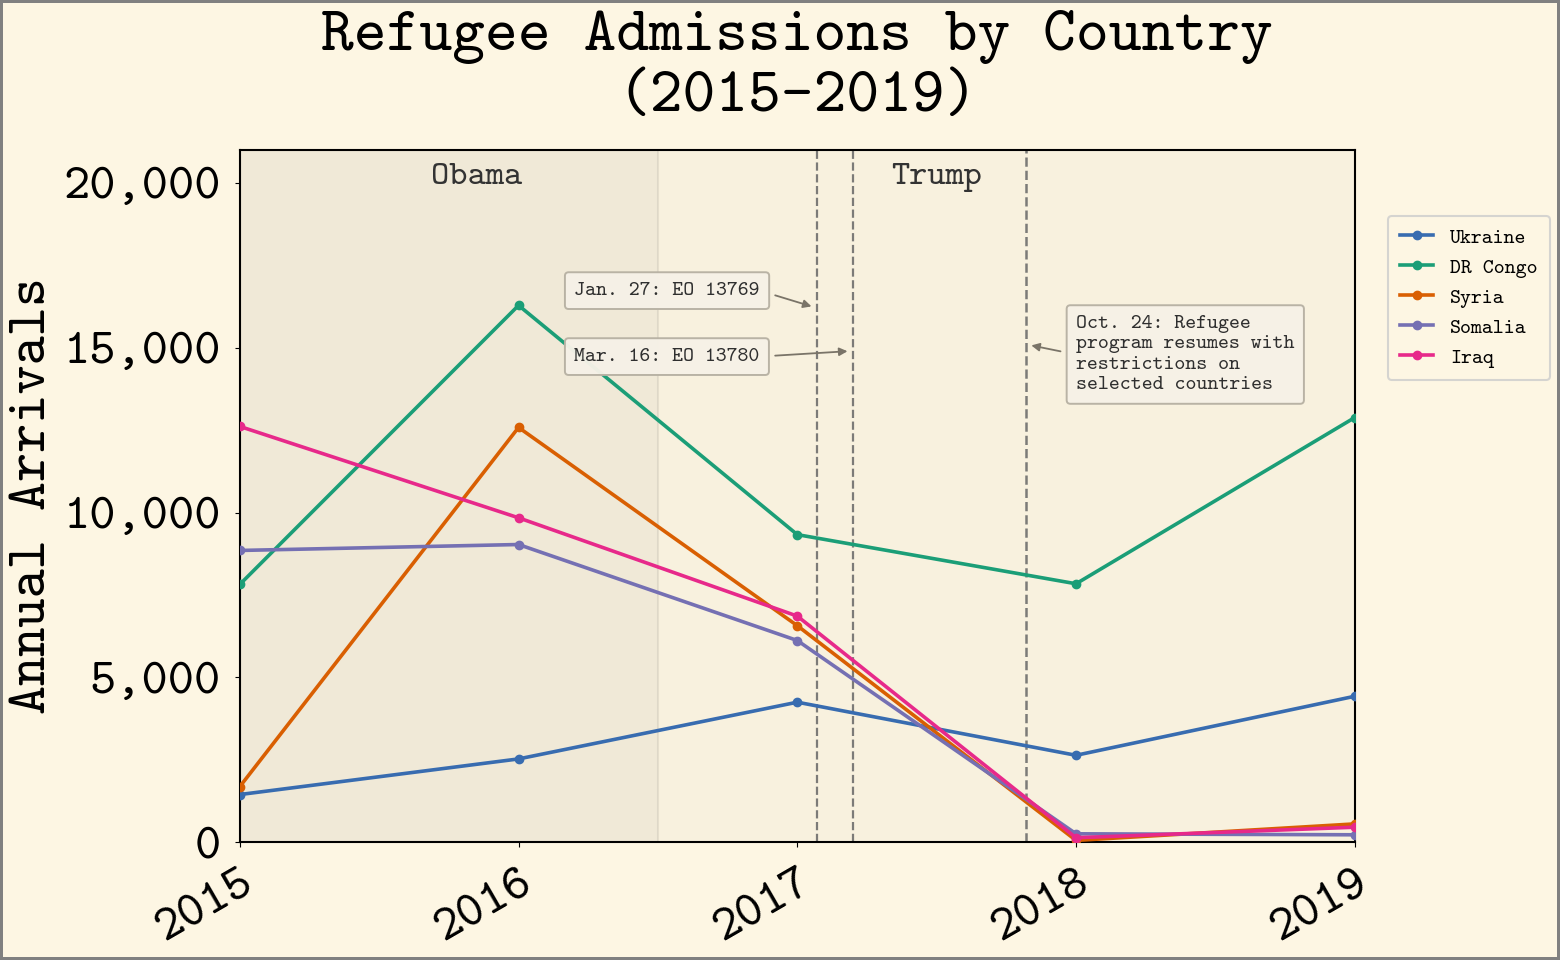

In [8]:
# 1. Apply custom style
plt.style.use("btt_style")

# 2. Define relevant countries
country_col = "Region and country of nationality"

target_countries = [
    "Syria",
    "Iraq",
    "Somalia",
    "Congo, Democratic Republic",
    "Ukraine",
]

# Clean strings
df_work = df_comb.copy()
df_work[country_col] = df_work[country_col].astype(str).str.strip()

# Filter for relevant countries
df_work = df_work[
    df_work[country_col].isin(target_countries)
].copy()

# 3. Clean year columns (2015 to 2019 only)
year_cols = [
    c for c in df_work.columns
    if str(c).strip().isdigit() and 2015 <= int(c) <= 2019
]

for col in year_cols:
    df_work[col] = (
        df_work[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .replace({"-": "0", "D": "0"})
    )
    df_work[col] = pd.to_numeric(df_work[col], errors="coerce").fillna(0)

# 4. Simplify labels
label_map = {
    "Syria": "Syria",
    "Iraq": "Iraq",
    "Somalia": "Somalia",
    "Congo, Democratic Republic": "DR Congo",
    "Ukraine": "Ukraine",
}

df_work["Country"] = df_work[country_col].map(label_map)

# Group in case there are duplicate rows
df_grouped = (
    df_work
    .groupby("Country")[year_cols]
    .sum()
    .reset_index()
)

# Melt to long format
df_long = df_grouped.melt(
    id_vars=["Country"],
    value_vars=year_cols,
    var_name="Year",
    value_name="Arrivals",
)

df_long["Year"] = df_long["Year"].astype(int)

# 5. Build visualization
fig, ax = plt.subplots()

# Presidency shading
presidencies = [
    ("Obama", 2015, 2016.5, "#000000", 0.05),
    ("Trump", 2016.5, 2019.5, "#000000", 0.02),
]

for name, start, end, color, alpha in presidencies:
    ax.axvspan(
        start,
        end,
        color=color,
        alpha=alpha,
        zorder=1,
    )

# Presidency labels
term_label_positions = {
    "Obama": 2015.85,
    "Trump": 2017.5,
}

for name in ["Obama", "Trump"]:
    ax.text(
        term_label_positions[name],
        20600,
        name,
        ha="center",
        va="top",
        fontsize=25,
        fontweight="bold",
        color="#333333",
        zorder=5,
    )

# Color palette
palette = {
    "Ukraine": "#386CB0",
    "DR Congo": "#1B9E77",
    "Syria": "#D95F02",
    "Somalia": "#7570B3",
    "Iraq": "#E7298A",
}

# Plot order
display_order = [
    "Ukraine",
    "DR Congo",
    "Syria",
    "Somalia",
    "Iraq",
]

for country in display_order:
    group = df_long[
        df_long["Country"] == country
    ].sort_values("Year")

    ax.plot(
        group["Year"],
        group["Arrivals"],
        marker="o",
        markersize=6,
        linewidth=2.6,
        label=country,
        color=palette.get(country),
        zorder=3,
    )

# 6. Policy annotation lines placed inside calendar 2017
# Jan. 27, 2017 ≈ 2017.07
# Mar. 16, 2017 ≈ 2017.20
# Oct. 24, 2017 ≈ 2017.82

policy_line_color = "#666666"

eo_13769_x = 2017.07
eo_13780_x = 2017.20
resume_x = 2017.82

ax.axvline(
    x=eo_13769_x,
    color=policy_line_color,
    linestyle="--",
    linewidth=1.6,
    alpha=0.85,
    zorder=2,
)

ax.axvline(
    x=eo_13780_x,
    color=policy_line_color,
    linestyle="--",
    linewidth=1.6,
    alpha=0.85,
    zorder=2,
)

ax.axvline(
    x=resume_x,
    color=policy_line_color,
    linestyle="--",
    linewidth=1.8,
    alpha=0.85,
    zorder=2,
)

# Callout box style
bbox_style = dict(
    boxstyle="round,pad=0.45,rounding_size=0.18",
    facecolor="#f6f1e7",
    edgecolor="#b7b1a3",
    linewidth=1.4,
    alpha=0.97,
)

arrow_style = dict(
    arrowstyle="-|>",
    color="#7a7468",
    linewidth=1.3,
    shrinkA=4,
    shrinkB=4,
    mutation_scale=12,
)

# Jan. 27 EO 13769 callout — arrow exits straight out of right side of box
ax.annotate(
    "Jan. 27: EO 13769",
    xy=(eo_13769_x, 16200),
    xytext=(2016.2, 17000),
    ha="left",
    va="top",
    fontsize=15,
    color="#2f2f2f",
    bbox=bbox_style,
    arrowprops=dict(
        **arrow_style,
        relpos=(1, 0.5),
        connectionstyle="arc3,rad=0",
    ),
    zorder=6,
)

# Mar. 16 EO 13780 callout — arrow exits straight out of right side of box
ax.annotate(
    "Mar. 16: EO 13780",
    xy=(eo_13780_x, 14900),
    xytext=(2016.2, 15000),
    ha="left",
    va="top",
    fontsize=15,
    color="#2f2f2f",
    bbox=bbox_style,
    arrowprops=dict(
        **arrow_style,
        relpos=(1, 0.5),
        connectionstyle="arc3,rad=0",
    ),
    zorder=6,
)

# Oct. 24 callout from the RIGHT — arrow exits straight out of left side of box
ax.annotate(
    "Oct. 24: Refugee\nprogram resumes with\nrestrictions on\nselected countries",
    xy=(resume_x, 15100),
    xytext=(2018.00, 16000),
    ha="left",
    va="top",
    fontsize=15,
    color="#2f2f2f",
    bbox=bbox_style,
    arrowprops=dict(
        **arrow_style,
        relpos=(0, 0.5),
        connectionstyle="arc3,rad=0",
    ),
    zorder=6,
)

# 7. Labels & limits
ax.set_title(
    "Refugee Admissions by Country\n(2015-2019)",
    pad=28,
)

ax.set_ylabel("Annual Arrivals")
ax.set_xlim(2015, 2019)
ax.set_ylim(0, 21000)

# Explicit year ticks
ax.set_xticks([2015, 2016, 2017, 2018, 2019])

# Rotate x labels slightly
plt.setp(
    ax.get_xticklabels(),
    rotation=30,
    ha="right",
    rotation_mode="anchor",
)

# Format y-axis labels
ax.yaxis.set_major_formatter("{x:,.0f}")

# Tick padding
ax.tick_params(axis="x", pad=10)
ax.tick_params(axis="y", pad=10)

# Legend outside plot on the right
ax.legend(
    frameon=True,
    loc="upper left",
    bbox_to_anchor=(1.02, 0.92),
    fontsize=15,
    labelspacing=0.5,
    handlelength=1.6,
    borderpad=0.6,
)

# Add room for external legend
fig.subplots_adjust(right=0.82)

# Force outer border thickness
fig.patch.set_linewidth(4)

fig.savefig(
    "timeseries_zoomed_2015_2019.png",
    dpi=600,
)

In [9]:

# Fact-check refugee admissions claims (2016 vs. 2018)

countries = [
    "Syria",
    "Somalia",
    "Iraq",
    "Congo, Democratic Republic",
    "Ukraine"
]

# Extract the original data
check = df_comb.copy()
country_col = "Region and country of nationality"

check[country_col] = check[country_col].astype(str).str.strip()
check = check[check[country_col].isin(countries)].copy()

# Clean numerical values
for year in ["2016", "2018"]:
    check[year] = pd.to_numeric(
        check[year].astype(str)
        .str.replace(",", "", regex=False)
        .replace({"-": "0", "D": "0"}),
        errors="coerce"
    )

# Aggregate by country
check = check.groupby(country_col)[["2016", "2018"]].sum()

# Combine the three Muslim-majority countries
muslim_countries = ["Syria", "Somalia", "Iraq"]

combined = check.loc[muslim_countries].sum()
congo = check.loc["Congo, Democratic Republic"]
ukraine = check.loc["Ukraine"]

# Calculate percentage changes
def pct_change(start, end):
    return (end - start) / start * 100

print("REFUGEE ADMISSIONS FACT CHECK")
print("=" * 55)

for label, values in [
    ("Syria + Somalia + Iraq", combined),
    ("DR Congo", congo),
    ("Ukraine", ukraine)
]:
    start = values["2016"]
    end = values["2018"]
    change = pct_change(start, end)

    print(f"\n{label}")
    print(f"2016 admissions: {start:,.0f}")
    print(f"2018 admissions: {end:,.0f}")
    print(f"Percentage change: {change:+.2f}%")

print("\nINDIVIDUAL COUNTRY DATA")
print(check.to_string())


REFUGEE ADMISSIONS FACT CHECK

Syria + Somalia + Iraq
2016 admissions: 31,450
2018 admissions: 460
Percentage change: -98.54%

DR Congo
2016 admissions: 16,280
2018 admissions: 7,840
Percentage change: -51.84%

Ukraine
2016 admissions: 2,530
2018 admissions: 2,640
Percentage change: +4.35%

INDIVIDUAL COUNTRY DATA
                                    2016  2018
Region and country of nationality             
Congo, Democratic Republic         16280  7840
Iraq                                9840   140
Somalia                             9030   260
Syria                              12580    60
Ukraine                             2530  2640
